## **Convergence analysis of the different algorithms**



In [1]:
#First we import the different algorithms and libraries
#EGPA algorithm
from EGPA import *

#CMAES algorithm
from pymoo.algorithms.soo.nonconvex.cmaes import CMAES
from pymoo.optimize import minimize
from pymoo.termination import get_termination


import numpy as np
import sys
import os
import pickle
# # Get the absolute path of the main directory
# main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# # Add the main directory to sys.path
# sys.path.append(main_dir)
import time
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [2]:
#We import the definitions of the optimization problems
from OptFunctions.oneDQHarmOscillatorfunctions import *
from pymooOptFunctions.pymooOptFunctions import *

vars = 50

###################################################################################
### STOP criteria for the algorithms ###
max_f_evals = 1*10**6 ##This is the main criteria to stop algorithm, max_f_evals = max_iter * size_gen.
###################################################################################

## It is necessary to define the grid with the variables ##
X_grid = np.linspace(start=-4, stop=4, num=vars).reshape(-1,1)
grid_size = ((X_grid[-1]-X_grid[0])/(len(X_grid)-1))
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array


#Energías teóricas
Eg = 0.5
En=[]
for i in range(4):
    e= Eg + 1*i
    En.append(e)

# X_grid = np.linspace(start=-4, stop=4, num=vars).reshape(-1,1)
# grid_size = ((X_grid[-1]-X_grid[0])/(len(X_grid)-1))

########################################################
#### Analytical solutions definitions ##################
########################################################
#Ground state
APsi0 = np.exp(-X_grid**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid**2/2)*2*X_grid
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = -1 * B * APsi1 #signo menos para correspondencia con solución algoritmo (simetrización)

#2nd excitated state
APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#if results_dict['eda_resultExpE2'].sel_inds_hist[-1, 0, :-1][3]<0:
# APsi2=-APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = -1 * B * APsi3 #signo menos para correspondencia con solución algoritmo (simetrización)

APsis = {}
APsis['APsi0'] = APsi0[:, 0]
APsis['APsi1'] = APsi1[:, 0]
APsis['APsi2'] = APsi2[:, 0]
APsis['APsi3'] = APsi3[:, 0]

In [3]:
#In the case of EGPA algorithm the parameters are optimized in a general way and not problem by problem.
ruta = f'EGPA_1D_experiments/BO_params/{vars}EGPA'
with open(f'{ruta}.pkl', "rb") as file:
    BO_params = pickle.load(file)

# for keys in BO_params.keys():
#     print(BO_params[keys])

size_gen = BO_params['params']['size_gen']
alpha = BO_params['params']['alpha']
elite_factor = BO_params['params']['elite_factor']
dead_iter = BO_params['params']['dead_iter'] #dead iter was optimized but it is not used. It is just a stop criteria for the algorithm which will be fixed.
init_kernels = BO_params['params']['init_kernels']
std_lower_bound = BO_params['params']['std_lower_bound']

#### STOP CRITERIA ##### based on max number of function evaluations fixed at 1 x 10^6
max_f_evals = 1*10**6 # max_f_evals = max_iter * size_gen.  
max_iter = int(max_f_evals/size_gen)
dead_iter = int(max_iter*0.05) #dead_iter = 5% of max_iter
#older criteria max_iter = 600 ##No se optimiza pero se fija para todos los exps.

#Nivel fundamental
### Ahora el código con EGPA que calcula los 4 primeros estados excitados del problema oscilador armónico
# params = {'x':X_grid}
# #Ground state
# print(f'F should be approx -0.082')
# Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
# egparesultQHOground = Gaussian.minimize(oneDHOExpE, params, exp_from = 10**8, output_runtime=True)

#Tercer estado excitado a partir de soluciones analíticas anteriores
params = {'x':X_grid, 'E0': En[0], 'Psi0':APsis['APsi0'], 'E1':En[1]-En[0], 'Psi1':APsis['APsi1'], 'E2':En[2]-En[1], 'Psi2':APsis['APsi2']}
Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
egparesultQHOground = Gaussian.minimize(oneDHOExpE3, params, exp_from = 10**8, output_runtime=True)

IT:  0 	Best cost:  [3.39988511]
IT:  1 	Best cost:  [2.99922972]
IT:  2 	Best cost:  [2.28782965]
IT:  3 	Best cost:  [2.28782965]
IT:  4 	Best cost:  [2.28782965]
IT:  5 	Best cost:  [2.28782965]
IT:  6 	Best cost:  [2.26762049]
IT:  7 	Best cost:  [2.20621455]
IT:  8 	Best cost:  [2.163755]
IT:  9 	Best cost:  [2.13485743]
IT:  10 	Best cost:  [2.06080895]
IT:  11 	Best cost:  [2.03916976]
IT:  12 	Best cost:  [2.00478102]
IT:  13 	Best cost:  [1.96839735]
IT:  14 	Best cost:  [1.92964178]
IT:  15 	Best cost:  [1.88302571]
IT:  16 	Best cost:  [1.84430926]
IT:  17 	Best cost:  [1.80459159]
IT:  18 	Best cost:  [1.76867031]
IT:  19 	Best cost:  [1.73390167]
IT:  20 	Best cost:  [1.70288097]
IT:  21 	Best cost:  [1.66619384]
IT:  22 	Best cost:  [1.63424919]
IT:  23 	Best cost:  [1.60009112]
IT:  24 	Best cost:  [1.57404307]
IT:  25 	Best cost:  [1.53832202]
IT:  26 	Best cost:  [1.50947458]
IT:  27 	Best cost:  [1.47843753]
IT:  28 	Best cost:  [1.45053609]
IT:  29 	Best cost:  [1.41

In [4]:
##########################################################################
############## C M A E S #################################################
#################################################################################
############## Quantum Harmonic Oscillator 1D ###################################
#################################################################################
#First we load the hyperparameters for this problem and this number of variables        
ruta = f'CMAES/CMAESBO_params/{vars}Osc'
with open(f'{ruta}.pkl', "rb") as file:
    BO_params = pickle.load(file)

sigma = BO_params['sigma']
pop_size = BO_params['pop_size']
restarts = BO_params['restarts']
bipop = BO_params['bipop']
incpopsize = BO_params['incpopsize']

### STOP criteria for algorithm ###
max_iter = int(max_f_evals/pop_size)
dead_iter = int(max_iter*0.05) #dead_iter = 5% of max_iter
termination = get_termination('soo', ftol=1e-10, period=dead_iter, n_max_gen=max_iter, n_max_evals=max_f_evals, xtol=1e-10)

# #Estado fundamental
# problem = pymoooOscGround(n_var=vars, grid=X_grid, eps=1e-4)
# algorithm = CMAES(sigma=sigma, pop_size=pop_size, restarts=restarts, bipop=bipop, incpopsize=incpopsize)#x0=initial_guess)
# resground = minimize(problem, algorithm, termination, verbose=True, save_history=True)#,seed=1,verbose=True)
# #Resultados[experimento, 0, 4] = resground.exec_time # 5 métricas [MSE, E, E%, GP_1000, t_exc]

#Prueba tercer estado excitado a partir de soluciones analíticas
problem = pymoooOsc3(n_var=vars, grid=X_grid, eps=1e-4, E0=En[0], Psi0=APsis['APsi0'], E1=En[1]-En[0], Psi1=APsis['APsi1'], E2=En[2]-En[1], Psi2=APsis['APsi2'])
algorithm = CMAES(sigma=sigma, pop_size=pop_size, restarts=restarts, bipop=bipop, incpopsize=incpopsize)#x0=initial_guess)
resground = minimize(problem, algorithm, termination, verbose=True, save_history=True)



n_gen  |  n_eval  |     f_avg     |     f_min     | run  |   fpop   | n_pop |     sigma     | min_std  | max_std  |   axis  
     1 |       20 |  1.208036E+03 |  6.670690E+02 |    1 |  6.7E+02 |    79 |  0.5079478204 |  0.50795 |  0.50797 |  1.00005
     2 |       99 |  1.238570E+03 |  4.612887E+02 |    1 |  4.6E+02 |    79 |  0.4767978479 |  0.47413 |  0.47961 |  1.08391
     3 |      178 |  1.183436E+03 |  3.979647E+02 |    1 |  4.0E+02 |    79 |  0.4614112442 |  0.45687 |  0.46526 |  1.10507
     4 |      257 |  1.083295E+03 |  3.979647E+02 |    1 |  4.9E+02 |    79 |  0.4542342158 |  0.44880 |  0.45897 |  1.12549
     5 |      336 |  1.019034E+03 |  3.979647E+02 |    1 |  4.7E+02 |    79 |  0.4725226344 |  0.46459 |  0.47769 |  1.13892
     6 |      415 |  1.100741E+03 |  3.979647E+02 |    1 |  4.1E+02 |    79 |  0.4780417690 |  0.47041 |  0.48732 |  1.14974
     7 |      494 |  9.821288E+02 |  3.820433E+02 |    1 |  3.8E+02 |    79 |  0.4777941057 |  0.46784 |  0.48898 |  1.16906


In [5]:
best_f_per_gen = []
global_best = np.inf  # initialize with something large

for algo in resground.history:
    F = algo.pop.get("F")
    # if F.ndim > 1:
    #     F = F[:, 0]  # choose the objective you care about if multi-objective

    # Best in current population
    best_now = np.min(F)

    # Update global best if improved
    if best_now < global_best:
        global_best = best_now

    best_f_per_gen.append(global_best)

In [6]:
#egparesultQHOground.data.shape
#(generations, individuals (just the best individual if analysis mode is off), variables + fitness)
#Para tener el fitness de este data seleccionamos: 
egparesultQHOground.data[:, 0, -1]

array([3.39988511, 2.99922972, 2.28782965, 2.28782965, 2.28782965,
       2.28782965, 2.26762049, 2.20621455, 2.163755  , 2.13485743,
       2.06080895, 2.03916976, 2.00478102, 1.96839735, 1.92964178,
       1.88302571, 1.84430926, 1.80459159, 1.76867031, 1.73390167,
       1.70288097, 1.66619384, 1.63424919, 1.60009112, 1.57404307,
       1.53832202, 1.50947458, 1.47843753, 1.45053609, 1.41936015,
       1.39682372, 1.37257263, 1.34587725, 1.31961917, 1.29642405,
       1.2732836 , 1.2478272 , 1.22315078, 1.20161973, 1.18381444,
       1.16514216, 1.14823531, 1.13149883, 1.11533882, 1.1022194 ,
       1.08467728, 1.07356991, 1.05818083, 1.04406181, 1.03353072,
       1.01997223, 1.01447998, 1.004887  , 0.99648691, 0.98964272,
       0.98371624, 0.97806846, 0.97355307, 0.96998978, 0.96772761,
       0.96570865, 0.96414364, 0.96364093, 0.96300438, 0.96253841,
       0.96211727, 0.96204383, 0.96199274, 0.9619026 , 0.96187298,
       0.96183093, 0.96182526, 0.96182443, 0.96182443, 0.96179

(-1.0, 200.0)

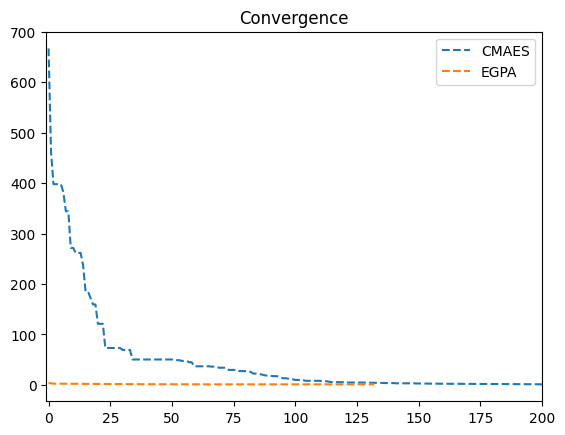

In [10]:
import matplotlib.pyplot as plt

plt.title("Convergence")
#plt.plot(n_evals, opt, "--", label='CMAES')
plt.plot(np.arange(start=0, stop=len(best_f_per_gen), step=1), best_f_per_gen,'--' ,label='CMAES')
plt.plot(np.arange(start=0, stop=len(egparesultQHOground.data[:, 0, -1]), step=1), egparesultQHOground.data[:,0,-1], '--',label='EGPA')
plt.legend()
# plt.yscale("log")
plt.xlim(-1, 200)
# plt.ylim(-0.01, 10)

In [8]:
np.min(resground.history[-1].pop.get('F'))

0.6968640981219388